# Climate-Sensitive Mortality Prediction

The score is `0.6 × F1 (at a fixed 0.5 threshold) + 0.4 × ROC-AUC`.

**Final picks on Zindi:**

| Submission | Model | CV (grouped) | Public LB |
|---|---|---|---|
| 5 | HistGB + CatBoost + TabPFN, features `age, year, post2017, under5_post, is_rural, is_male` | ~0.820 | 0.8414 |
| 9 | Tuned HistGB 0.7 + tuned CatBoost 0.3, the same features + `tmin_30d_infant_pre` | 0.8236 | 0.8354 |


### How to run

- **Dependencies:** `pip install -r requirements.txt` (LightGBM needs `brew install libomp` on macOS).
- **Data:** competition files in `data/raw/`. ERA5 weather (external) is downloaded once by `src/external.py` and cached in `data/external/`.
- **Helpers:** data loading, grouped CV, models and submission checks live in [`src/modelling.py`](modelling.py) and [`src/external.py`](external.py)
- Every model uses fixed seeds (42, plus seed lists for averaging). 

## 0. Setup

In [2]:
# imports
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import SplineTransformer

In [ ]:
# source imports
sys.path.append("..") 

from src.external import add_era5_features, add_temperature_lag_features
from src.modelling import (
    TARGET, AgeSplitModel, AveragedModel, ColumnModel, Experiments, load_data,
    location_groups, make_model, make_submission, seed_average, set_seeds, 
)

In [ ]:
set_seeds()  # seed 42 for Python and NumPy

DATA_DIR = "../data/raw"
SUBMISSIONS_DIR = "../submissions"

RUN_SLOW_SEARCHES = False  # hyperparameter grids / random searches 
RUN_TABPFN = False         # TabPFN v2 needs `pip install tabpfn`

In [5]:
def without(columns, columns_to_remove):
    """A copy of `columns` without the ones in `columns_to_remove`."""
    kept = []
    for column in columns:
        if column not in columns_to_remove:
            kept.append(column)
    return kept


def with_setting(params, name, value):
    """A copy of a hyperparameter dict with one setting changed."""
    changed = dict(params)
    changed[name] = value
    return changed

In [6]:
# Train, test and the sample submission, with climate_features.csv joined on ID.
# load_data also adds is_rural, is_male and year.
train, test, sample_submission = load_data(DATA_DIR)
print("Train:", train.shape)
print("Test:", test.shape)
train.head()

Train: (3146, 31)
Test: (1030, 30)


,ID,zone,gender,deathdate,age,avg_temperature,max_temperature,min_temperature,precipitation,latitude,...,slope,tavg_30d,tavg_7d,tavg_90d,temp_range_mean_30d,tmax_30d,tmin_30d,is_rural,is_male,year
0,ID_1FE951BD,Rural,Male,2007-10-02,30.0,21.137037,25.569017,18.451642,0.951601,0.584646,...,0.168545,21.425953,22.012127,21.043539,7.897970,27.608331,16.132043,1,1,2007
1,ID_5927A443,Rural,Male,2008-01-05,2.0,24.062790,29.312026,18.977212,0.053352,0.549565,...,0.299996,22.129209,23.021381,21.992129,8.735769,29.251932,15.591455,1,1,2008
2,ID_C4E67025,Rural,Female,2008-02-14,31.0,22.407868,26.746058,18.112977,0.090349,0.573420,...,0.299996,21.990516,21.557252,22.220307,7.694241,29.083597,17.420068,1,0,2008
3,ID_44DC5CE9,Rural,Female,2008-02-15,1.0,23.315198,28.056889,18.955708,0.286814,0.549565,...,0.299996,22.032392,21.693581,22.231408,7.718027,29.083597,17.420068,1,0,2008
4,ID_33C677BB,Rural,Female,2008-02-15,69.0,23.315198,28.056889,18.955708,0.286814,1.072343,...,5.565486,20.143552,20.141416,20.510054,10.152887,28.300394,12.632257,1,0,2008


## 1. EDA

In [7]:
def rate_table(df, by):
    """Climate-sensitive rate and row count for each value of `by`."""
    grouped = df.groupby(by, observed=True)[TARGET]
    table = grouped.agg(rate="mean", rows="size")
    return table.round(3)

In [8]:
# Data quality
print("Missing values (train, test):", train.isna().sum().sum(), test.isna().sum().sum())
print("Duplicate rows:", train.drop(columns="ID").duplicated().sum())
print("Train dates:", train["deathdate"].min().date(), "to", train["deathdate"].max().date())
print("Test dates: ", test["deathdate"].min().date(), "to", test["deathdate"].max().date())
print("Positive rate:", round(train[TARGET].mean(), 3))

Missing values (train, test): 0 0
Duplicate rows: 2
Train dates: 2007-10-02 to 2022-12-13
Test dates:  2007-11-24 to 2022-05-17
Positive rate: 0.651


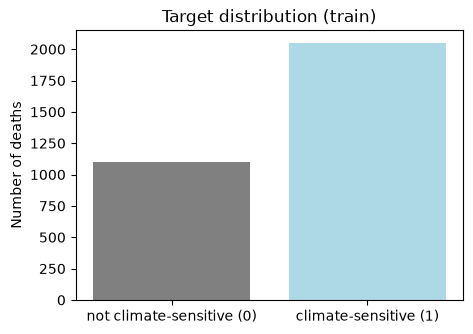

In [9]:
# Target distribution
target_counts = train[TARGET].value_counts().sort_index()
plt.figure(figsize=(5, 3.5))
plt.bar(["not climate-sensitive (0)", "climate-sensitive (1)"], target_counts.values, color=["grey", "lightblue"])
plt.title("Target distribution (train)")
plt.ylabel("Number of deaths")
plt.show()

About two-thirds of deaths are climate-sensitive

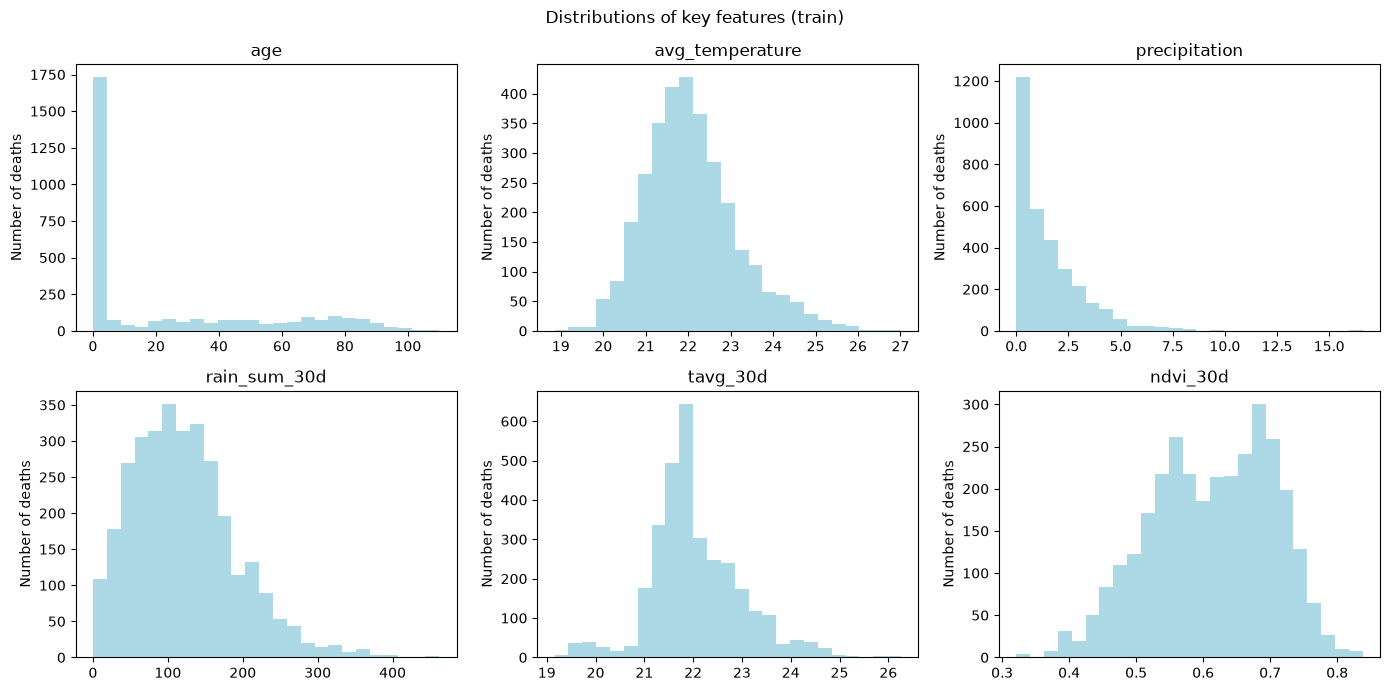

In [10]:
# Distributions of the main numeric features
key_numeric = ["age", "avg_temperature", "precipitation", "rain_sum_30d", "tavg_30d", "ndvi_30d"]
figure, axes = plt.subplots(2, 3, figsize=(14, 7))
for i in range(len(key_numeric)):
    axes.flatten()[i].hist(train[key_numeric[i]], bins=25, color="lightblue")
    axes.flatten()[i].set_title(key_numeric[i])
    axes.flatten()[i].set_ylabel("Number of deaths")
plt.suptitle("Distributions of key features (train)")
plt.tight_layout()
plt.show()

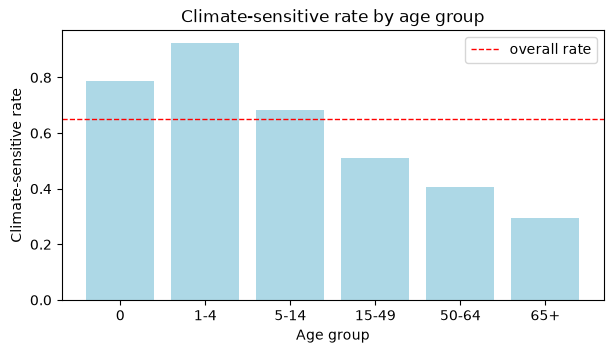

age,0,1-4,5-14,15-49,50-64,65+
rate,0.788,0.923,0.684,0.51,0.406,0.296
rows,1112.000,621.000,117.000,525.00,197.000,574.000


In [59]:
# Age is the strongest signal: the rate rises from infants to toddlers, then falls with age
age_group = pd.cut(train["age"], [-1, 0, 4, 14, 49, 64, 200], labels=["0", "1-4", "5-14", "15-49", "50-64", "65+"])
rate_by_age = rate_table(train, age_group)

plt.figure(figsize=(7, 3.5))
plt.bar(rate_by_age.index.astype(str), rate_by_age["rate"], color="lightblue")
plt.axhline(train[TARGET].mean(), color="red", linestyle="--", linewidth=1, label="overall rate")
plt.title("Climate-sensitive rate by age group")
plt.xlabel("Age group")
plt.ylabel("Climate-sensitive rate")
plt.legend()
plt.show()
rate_by_age.T

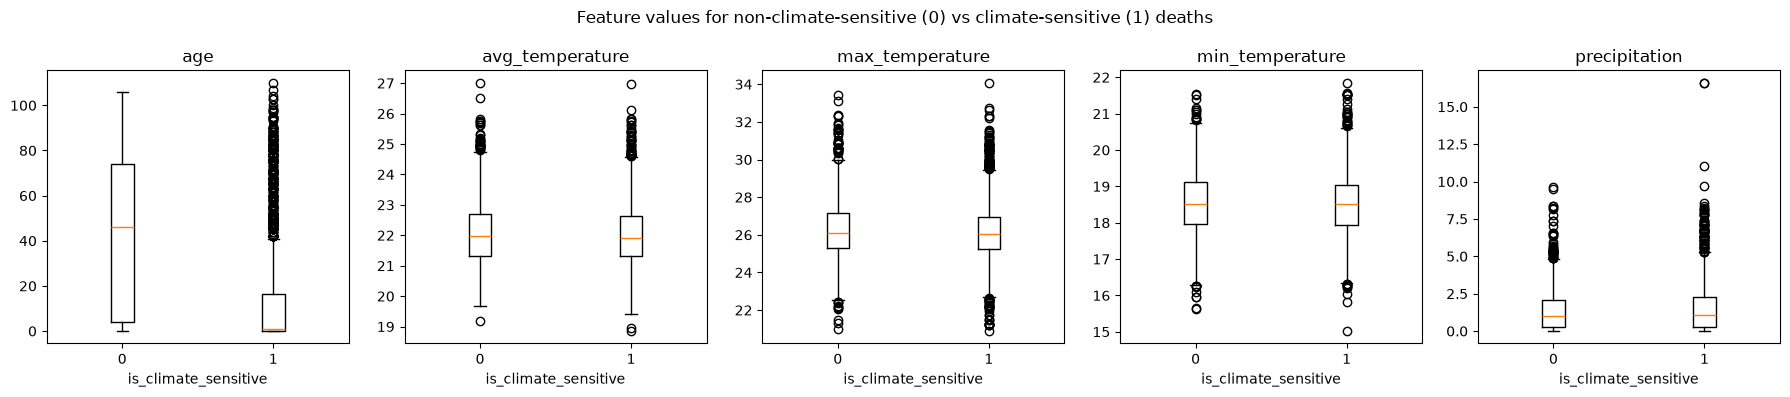

In [11]:
# Box plots by target: age separates the classes clearly; same-day weather barely does
boxplot_columns = ["age", "avg_temperature", "max_temperature", "min_temperature", "precipitation"]
figure, axes = plt.subplots(1, len(boxplot_columns), figsize=(18, 4))
for axis, column in zip(axes, boxplot_columns):
    values_negative = train.loc[train[TARGET] == 0, column]
    values_positive = train.loc[train[TARGET] == 1, column]
    axis.boxplot([values_negative, values_positive])
    axis.set_xticks([1, 2])
    axis.set_xticklabels(["0", "1"])
    axis.set_title(column)
    axis.set_xlabel("is_climate_sensitive")
plt.suptitle("Feature values for non-climate-sensitive (0) vs climate-sensitive (1) deaths")
plt.tight_layout()
plt.show()

In [12]:
# Zone and gender barely matter on their own
display(rate_table(train, "zone").T)
display(rate_table(train, "gender").T)

zone,Peri_urban,Rural
rate,0.641,0.657
rows,1174.000,1972.000


gender,Female,Male
rate,0.672,0.632
rows,1501.000,1645.000


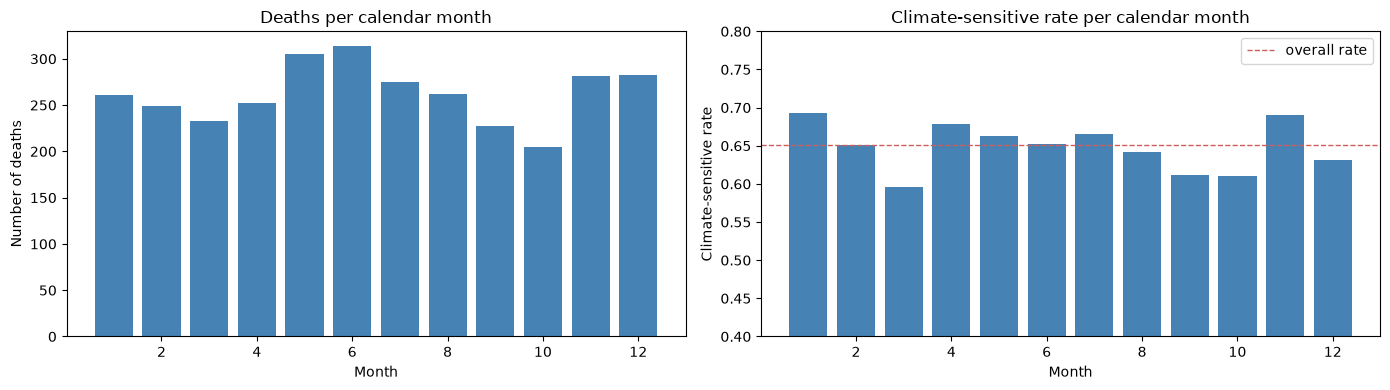

In [15]:
# Death counts peak after the rainy seasons (Mar-May, Sep-Nov), but the climate-sensitive rate barely moves
month = train["deathdate"].dt.month
deaths_per_month = month.value_counts().sort_index()
rate_per_month = train.groupby(month)[TARGET].mean()

figure, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].bar(deaths_per_month.index, deaths_per_month.values, color="steelblue")
axes[0].set_title("Deaths per calendar month")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Number of deaths")
axes[1].bar(rate_per_month.index, rate_per_month.values, color="steelblue")
axes[1].axhline(train[TARGET].mean(), color="indianred", linestyle="--", linewidth=1, label="overall rate")
axes[1].set_title("Climate-sensitive rate per calendar month")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Climate-sensitive rate")
axes[1].set_ylim(0.4, 0.8)
axes[1].legend()
plt.tight_layout()
plt.show()

**Test is at different villages from Train.** That's why all validation below is grouped by location.

In [14]:
unseen_rows = ~test["location"].isin(train["location"])
print(f"Test locations not in train: {test.loc[unseen_rows, 'location'].nunique()} of {test['location'].nunique()}")
print(f"Test rows at those locations: {unseen_rows.sum()} of {len(test)}")
print(f"Test is rural: {test['is_rural'].mean():.2f} vs train {train['is_rural'].mean():.2f}")

Test locations not in train: 10 of 11
Test rows at those locations: 1004 of 1030
Test is rural: 0.76 vs train 0.63


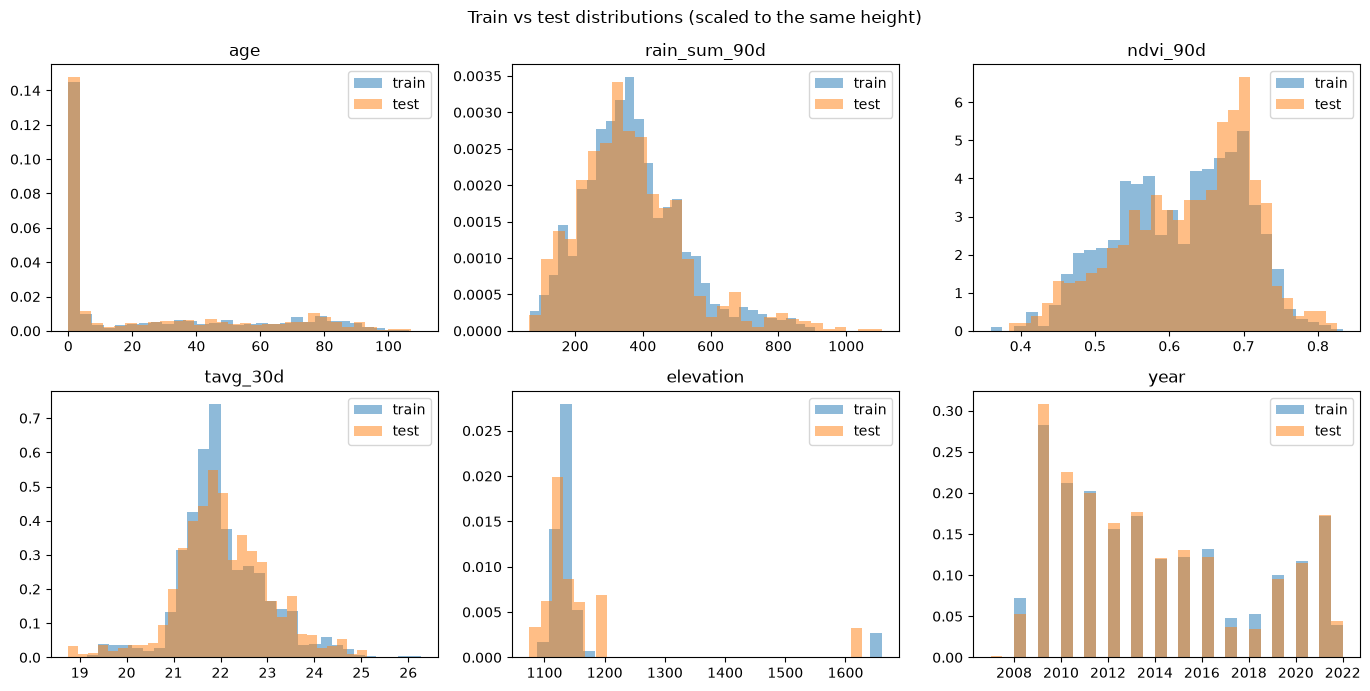

In [ ]:
# Train vs test distributions of key columns
compare_columns = ["age", "rain_sum_90d", "ndvi_90d", "tavg_30d", "elevation", "year"]
figure, axes = plt.subplots(2, 3, figsize=(14, 7))
for i in range(len(compare_columns)):
    column = compare_columns[i]
    axes.flatten()[i].hist(train[column], bins=30, alpha=0.5, density=True, label="train")
    axes.flatten()[i].hist(test[column], bins=30, alpha=0.5, density=True, label="test")
    axes.flatten()[i].set_title(column)
    axes.flatten()[i].legend()
plt.suptitle("Train vs test distributions (scaled to the same height)")
plt.tight_layout()
plt.show()

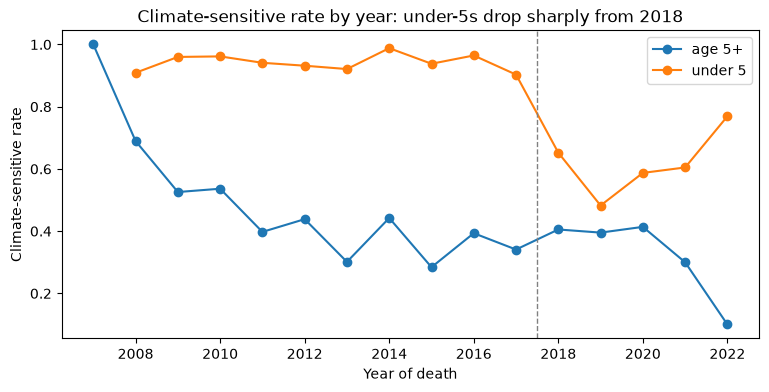

mean              size            
     2018+ before 2018 2018+ before 2018
age                                     
0     0.56        0.97   492         620
1-4   0.88        0.93    56         565
5-14  0.71        0.67    35          82
15+   0.29        0.42   173        1123

In [12]:
age_band = np.where(train["age"] < 5, "under 5", "age 5+")
rate_by_year = train.groupby(["year", age_band])[TARGET].mean()
rate_by_year = rate_by_year.unstack()  # one column per age band

rate_by_year.plot(marker="o", figsize=(9, 4))
plt.axvline(2017.5, color="grey", linestyle="--", linewidth=1)
plt.title("Climate-sensitive rate by year: under-5s drop sharply from 2018")
plt.xlabel("Year of death")
plt.ylabel("Climate-sensitive rate")
plt.show()

# Infants vs toddlers before and after 2018
age_detail = pd.cut(train["age"], [-1, 0, 4, 14, 200], labels=["0", "1-4", "5-14", "15+"])
period = np.where(train["year"] >= 2018, "2018+", "before 2018")
rate_by_age_and_period = train.groupby([age_detail, period], observed=True)[TARGET].agg(["mean", "size"])
rate_by_age_and_period.unstack().round(2)

The under-5 rate is about 90–99% until 2017, then drops to about 48–65%. From 2018, under-5 deaths are almost all infants, whose rate falls from 97% to 56%. It looks like newborn deaths started being recorded, which is a recording change rather than a climate effect, so `year` matters a lot.

In [ ]:
# Does Test have the same mix of these groups as Train? Yeah
def group_mix(df):
    return pd.Series({
        "infants 2018+": ((df["age"] == 0) & (df["year"] >= 2018)).mean(),
        "under-5 before 2018": ((df["age"] < 5) & (df["year"] < 2018)).mean(),
        "5+ before 2018": ((df["age"] >= 5) & (df["year"] < 2018)).mean(),
        "5+ 2018+": ((df["age"] >= 5) & (df["year"] >= 2018)).mean(),
    })


pd.DataFrame({"train": group_mix(train), "test": group_mix(test)}).round(3)

,train,test
infants 2018+,0.156,0.144
under-5 before 2018,0.377,0.380
5+ before 2018,0.383,0.389
5+ 2018+,0.066,0.066


In [18]:
CLIMATE_COLUMNS = [
    "rain_sum_7d", "rain_sum_30d", "rain_sum_90d", "max_daily_rain_30d", "rain_days_30d",
    "ndvi_30d", "ndvi_90d", "tavg_30d", "tmax_30d", "tmin_30d", "temp_range_mean_30d",
    "avg_temperature", "max_temperature", "min_temperature", "precipitation",
]


def signal_strength(df, column):
    """|AUC - 0.5| of one column used on its own: 0 = no signal."""
    return abs(roc_auc_score(df[TARGET], df[column]) - 0.5)


under5_rows = train[train["age"] < 5]
signal_rows = []
for column in CLIMATE_COLUMNS + ["age"]:
    signal_rows.append({
        "column": column,
        "all": signal_strength(train, column),
        "under 5": signal_strength(under5_rows, column),
    })
climate_signal = pd.DataFrame(signal_rows).set_index("column")
climate_signal = climate_signal.sort_values("all", ascending=False)
climate_signal.round(3)

,all,under 5
column,,
age,0.234,0.106
max_daily_rain_30d,0.038,0.082
ndvi_90d,0.028,0.034
ndvi_30d,0.024,0.039
rain_sum_30d,0.020,0.063
rain_sum_90d,0.019,0.076
max_temperature,0.017,0.023
rain_sum_7d,0.016,0.043
temp_range_mean_30d,0.014,0.020


Each climate column on its own barely separates the classes (|AUC − 0.5| ≤ 0.04 overall), with slightly more signal for under-5s.

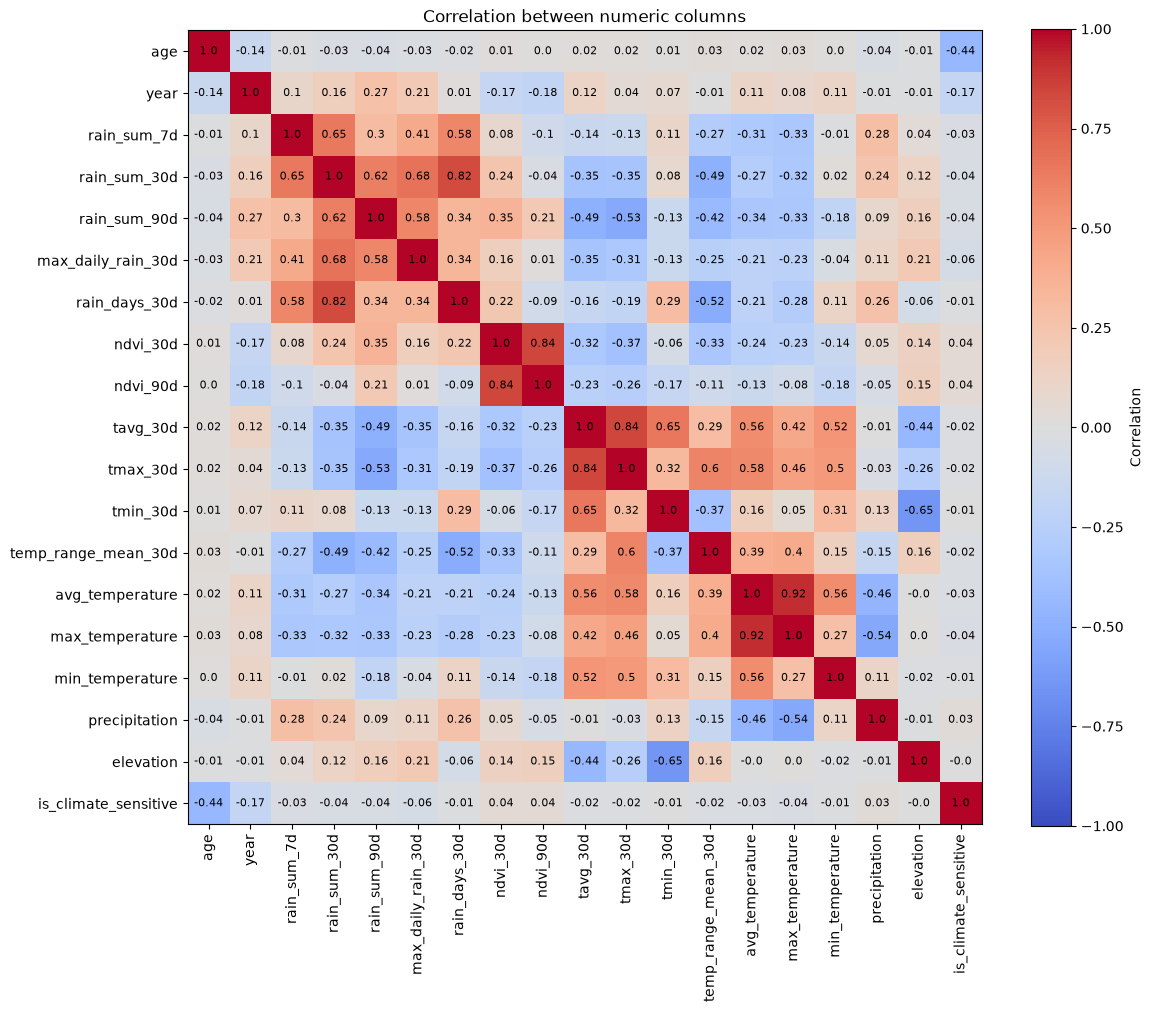

,column_1,column_2,correlation
0,rain_sum_30d,rain_days_30d,0.82
1,ndvi_30d,ndvi_90d,0.84
2,tavg_30d,tmax_30d,0.84
3,avg_temperature,max_temperature,0.92


In [19]:
# Correlation between numeric columns
heatmap_columns = ["age", "year"] + CLIMATE_COLUMNS + ["elevation", TARGET]
correlation = train[heatmap_columns].corr()

plt.figure(figsize=(12, 10))
plt.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")

plt.xticks(range(len(heatmap_columns)), heatmap_columns, rotation=90)
plt.yticks(range(len(heatmap_columns)), heatmap_columns)
plt.title("Correlation between numeric columns")

# Add correlation scores inside each cell
for i in range(len(heatmap_columns)):
    for j in range(len(heatmap_columns)):
        plt.text(j, i, round(correlation.iloc[i, j], 2),
                 ha="center", va="center", fontsize=8)

plt.tight_layout()
plt.show()

# Pairs of columns with correlation above 0.8
strong_pairs = []

for i in range(len(heatmap_columns)):
    for j in range(i + 1, len(heatmap_columns)):
        value = correlation.iloc[i, j]

        if abs(value) > 0.8:
            strong_pairs.append({
                "column_1": heatmap_columns[i],
                "column_2": heatmap_columns[j],
                "correlation": round(value, 2)
            })

pd.DataFrame(strong_pairs)

## 2. Features

All features used anywhere in the notebook are built here, once, so later sections don't depend on each other.

In [20]:
def add_engineered_features(df, monthly_norms):
    """Feature-engineering ideas from engineering.ipynb (section 4 tests them)."""
    df = df.copy()

    # Age features
    df["is_infant"] = (df["age"] == 0).astype(int)
    df["under5"] = (df["age"] < 5).astype(int)
    df["age_group"] = pd.cut(df["age"], bins=[-1, 0, 4, 14, 49, 64, 200], labels=False)  # 0 = infant ... 5 = 65+
    df["age_0to4"] = df["age"].clip(upper=5)  # single years 0-4, everyone 5+ lumped together

    # Age x rain: the rain value for under-5s, blank (NaN) for everyone else
    for col in ["rain_sum_90d", "rain_sum_30d", "max_daily_rain_30d"]:
        df[f"{col}_under5"] = df[col].where(df["under5"] == 1)

    # Rain trends (+1 avoids dividing by zero)
    df["rain_ratio_7_30"] = df["rain_sum_7d"] / (df["rain_sum_30d"] + 1)
    df["rain_ratio_30_90"] = df["rain_sum_30d"] / (df["rain_sum_90d"] + 1)
    df["dry_days_30d"] = 30 - df["rain_days_30d"]

    # Anomalies: difference from the normal for that calendar month
    norms = monthly_norms.loc[df["deathdate"].dt.month].set_index(df.index)
    for col in monthly_norms.columns:
        df[f"{col}_anom"] = df[col] - norms[col]
    return df

In [21]:
def add_regime_features(df):
    """Time and subgroup features used from submission 5 on."""
    df = df.copy()
    df["month"] = df["deathdate"].dt.month
    df["post2017"] = (df["year"] >= 2018).astype(int)          # the 2018 regime change
    df["under5_post"] = df["under5"] * df["post2017"]
    df["infant_post"] = df["is_infant"] * df["post2017"]
    df["adult_post"] = (1 - df["under5"]) * df["post2017"]

    # Climate columns kept only for pre-2018 infants (blank for everyone else): the one group with real signal
    infant_pre2018 = (df["age"] == 0) & (df["year"] < 2018)
    for col in ["elevation", "tmin_30d", "month"]:
        df[f"{col}_infant_pre"] = df[col].where(infant_pre2018)

    # Climate columns kept only for ages 5+ (blank for children), for the adult experiments
    for col in ["rain_sum_30d", "rain_sum_90d", "max_daily_rain_30d", "ndvi_90d", "tavg_30d",
                "tmin_30d", "temp_range_mean_30d", "elevation", "month", "rh_8_12w"]:
        df[f"{col}_adult"] = df[col].where(df["age"] >= 5)
    return df

In [22]:
# Monthly "normal" weather from all rows of climate_features.csv (train + test; no target involved)
climate_raw = pd.read_csv(f"{DATA_DIR}/climate_features.csv", parse_dates=["deathdate"])
anomaly_columns = ["rain_sum_7d", "rain_sum_30d", "rain_sum_90d", "max_daily_rain_30d", "ndvi_30d", "ndvi_90d", "tavg_30d"]
monthly_norms = climate_raw.groupby(climate_raw["deathdate"].dt.month)[anomaly_columns].mean()

In [23]:
# External ERA5 weather (Open-Meteo). Downloads once, then reads the cache in data/external/.
train, test, ERA5_FEATURES = add_era5_features(train, test, cache_dir="../data/external")
train, test, TEMPERATURE_LAG_FEATURES = add_temperature_lag_features(train, test, cache_dir="../data/external")

train = add_regime_features(add_engineered_features(train, monthly_norms))
test = add_regime_features(add_engineered_features(test, monthly_norms))
print("Train:", train.shape, "| Test:", test.shape)
print("ERA5 features:", ERA5_FEATURES)
print("Temperature lag features:", TEMPERATURE_LAG_FEATURES)

ERA5 grid cells: 15/15
ERA5 grid cells: 15/15
Train: (3146, 78) | Test: (1030, 77)
ERA5 features: ['era5_rain_0_4w', 'era5_rain_4_8w', 'era5_rain_8_12w', 'rh_0_4w', 'rh_8_12w', 'dew_0_4w', 'soil_0_4w', 'soil_8_12w', 'vpd_0_4w']
Temperature lag features: ['tmax_lag_5_11w', 'tmean_lag_5_11w', 'malaria_temp_days_5_11w']


## 3. Validation

Test villages are unseen, so I score every model with **5-fold `StratifiedGroupKFold` grouped by location**: each fold is scored on villages the model never trained on. Two location names that are really the same place are merged first (37 groups).

Gains are small, so each experiment is **repeated over several random fold splits** and averaged: 5 splits for submissions 1–6, 10 splits from submission 7. **My rule for keeping a change:** it beats the baseline on the mean *and* on most splits (7+ of 10), with a normal predicted-positive rate (≤ 0.75).

In [17]:
# One tracker per number of splits. Every experiment with the same tracker uses the same folds.
cv5 = Experiments(train, n_splits=5, split_seeds=[0, 1, 2, 3, 4])
cv10 = Experiments(train, n_splits=5, split_seeds=list(range(10)))

# Check the folds of the first split: similar size and target rate, and no village in two folds
groups = location_groups(train)
print("Location groups:", groups.nunique())
for fold, (train_idx, valid_idx) in enumerate(cv5.splits[0]):
    shared = set(groups.iloc[train_idx]) & set(groups.iloc[valid_idx])
    print(f"Fold {fold}: {len(valid_idx)} rows, {groups.iloc[valid_idx].nunique()} locations, "
          f"target rate {train[TARGET].iloc[valid_idx].mean():.3f}, villages shared with training: {len(shared)}")

Location groups: 37
Fold 0: 618 rows, 5 locations, target rate 0.634, villages shared with training: 0
Fold 1: 635 rows, 10 locations, target rate 0.666, villages shared with training: 0
Fold 2: 640 rows, 7 locations, target rate 0.659, villages shared with training: 0
Fold 3: 645 rows, 9 locations, target rate 0.654, villages shared with training: 0
Fold 4: 608 rows, 6 locations, target rate 0.638, villages shared with training: 0


### Baselines

Testing: how good is "predict everyone positive", and how much does age alone add?

all_ones: 0.6729 (worst split 0.6728)
age_only: 0.7922 (worst split 0.7894)


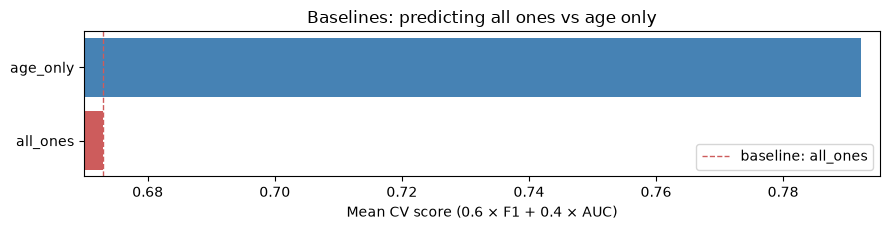

,mean,worst_split,gain_vs_baseline,splits_beating_baseline,pred_pos_rate
age_only,0.7922,0.7894,0.1193,5,0.7063
all_ones,0.6729,0.6728,0.0000,0,1.0000


In [18]:
# Small, regularised HistGB used for the baseline and the feature-engineering tests
HISTGB_START = {"max_depth": 3, "max_iter": 200, "learning_rate": 0.05, "min_samples_leaf": 40}

cv5.run("all_ones", DummyClassifier(strategy="constant", constant=1), ["age"])  # ignores its input
cv5.run("age_only", make_model("histgb", HISTGB_START), ["age"])
cv5.compare(["age_only"], baseline="all_ones", title="Baselines: predicting all ones vs age only")

**Result:** all-ones scores 0.673 (F1 0.79, AUC 0.50). Age alone scores **0.792**, almost entirely through AUC. Getting a decent F1 is easy because 65% of deaths are positive; the room to improve is in *ranking* deaths well.

## 4. Feature engineering

Testing: four groups of engineered features, added one at a time on top of age (same small HistGB).

fe_age_features: 0.7922 (worst split 0.7894)
fe_+climate: 0.8000 (worst split 0.7988)
fe_+interactions: 0.7989 (worst split 0.7974)
fe_+rain_trends: 0.7981 (worst split 0.7947)
fe_+anomalies: 0.7984 (worst split 0.7957)


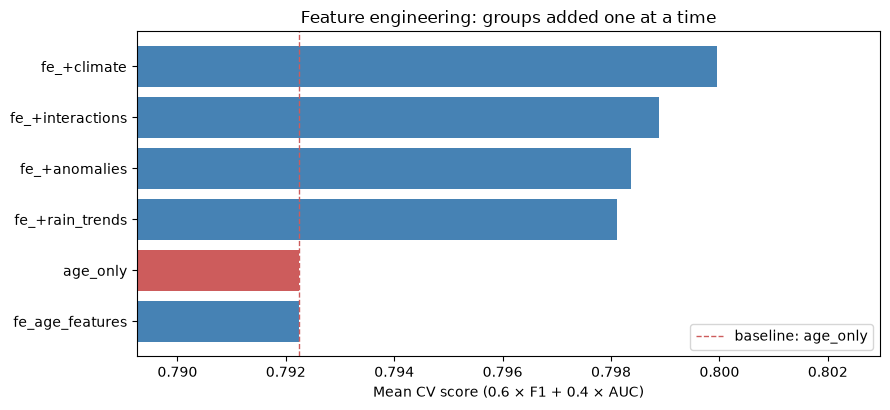

,mean,worst_split,gain_vs_baseline,splits_beating_baseline,pred_pos_rate
fe_+climate,0.8000,0.7988,0.0077,5,0.7013
fe_+interactions,0.7989,0.7974,0.0066,5,0.6950
fe_+anomalies,0.7984,0.7957,0.0061,5,0.6923
fe_+rain_trends,0.7981,0.7947,0.0059,5,0.6972
age_only,0.7922,0.7894,0.0000,0,0.7063
fe_age_features,0.7922,0.7894,0.0000,0,0.7063


In [19]:
AGE_FEATURES = ["age", "is_infant", "under5", "age_group", "age_0to4"]
INTERACTION_FEATURES = ["rain_sum_90d_under5", "rain_sum_30d_under5", "max_daily_rain_30d_under5"]
RAIN_TREND_FEATURES = ["rain_ratio_7_30", "rain_ratio_30_90", "dry_days_30d"]
ANOMALY_FEATURES = []
for column in anomaly_columns:
    ANOMALY_FEATURES.append(f"{column}_anom")

feature_groups = {
    "fe_age_features": AGE_FEATURES,
    "fe_+climate": AGE_FEATURES + CLIMATE_COLUMNS,
    "fe_+interactions": AGE_FEATURES + CLIMATE_COLUMNS + INTERACTION_FEATURES,
    "fe_+rain_trends": AGE_FEATURES + CLIMATE_COLUMNS + INTERACTION_FEATURES + RAIN_TREND_FEATURES,
    "fe_+anomalies": AGE_FEATURES + CLIMATE_COLUMNS + INTERACTION_FEATURES + RAIN_TREND_FEATURES + ANOMALY_FEATURES,
}
for name, features in feature_groups.items():
    cv5.run(name, make_model("histgb", HISTGB_START), features)

cv5.compare(list(feature_groups), baseline="age_only", title="Feature engineering: groups added one at a time")

**Result:** only the raw climate columns helped (0.8000, +0.008, all 5 splits). The extra age features change nothing (the trees already find the age cut-offs), and interactions, rain trends and anomalies add nothing on top of raw climate. So I kept **age + raw climate** and dropped the engineered groups.

## 5. Submissions

Each submission states what changed and why, runs its experiments, compares them with a bar chart, and builds its final model (the export line is commented out).

### Submission 1: age + raw climate

Testing: the best setup from feature engineering, as a first submission.

In [20]:
FEATURES_AGE_CLIMATE = ["age"] + CLIMATE_COLUMNS

cv5.run("sub1", make_model("histgb", HISTGB_START), FEATURES_AGE_CLIMATE)

final_model_sub1 = make_model("histgb", HISTGB_START)
# make_submission(final_model_sub1, train, test, FEATURES_AGE_CLIMATE, sample_submission, path=f"{SUBMISSIONS_DIR}/submission1.csv")

sub1: 0.8000 (worst split 0.7988)


**Result:** CV 0.800, **public 0.8055**. The public score matched CV, so the grouped CV was trustworthy.

### Submission 2: zone and gender, CatBoost, and tuning

Testing: adding `zone` and `gender`, trimming duplicate climate columns, CatBoost, and a hyperparameter grid.

In [21]:
FEATURES_ZONE_GENDER = FEATURES_AGE_CLIMATE + ["is_rural", "is_male"]
FEATURES_TRIMMED = without(FEATURES_AGE_CLIMATE, ["avg_temperature", "max_temperature"])

CATBOOST_SUB2 = {"depth": 4, "learning_rate": 0.03, "iterations": 600, "l2_leaf_reg": 3}
CATBOOST_SUB2_SMALL = {"depth": 3, "learning_rate": 0.03, "iterations": 400, "l2_leaf_reg": 5}

cv5.run("sub2_zone_gender", make_model("histgb", HISTGB_START), FEATURES_ZONE_GENDER)
cv5.run("sub2_trimmed_climate", make_model("histgb", HISTGB_START), FEATURES_TRIMMED)
cv5.run("sub2_catboost", make_model("catboost", CATBOOST_SUB2), FEATURES_ZONE_GENDER)
cv5.run("sub2_catboost_small", make_model("catboost", CATBOOST_SUB2_SMALL), FEATURES_ZONE_GENDER)

sub2_zone_gender: 0.8042 (worst split 0.8021)
sub2_trimmed_climate: 0.7989 (worst split 0.7973)
sub2_catboost: 0.7994 (worst split 0.7976)
sub2_catboost_small: 0.8021 (worst split 0.8013)


sub2_tuned: 0.8067 (worst split 0.8036)
sub2_blend_tuned_catboost: 0.8057 (worst split 0.8041)


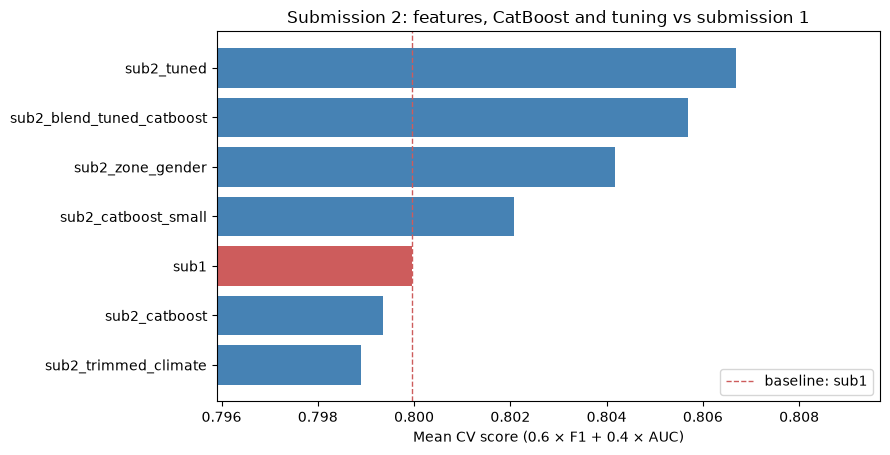

In [22]:
# Tuning grid (72 combinations, about 8 minutes). Off by default: the winner is written below.
if RUN_SLOW_SEARCHES:
    grid_sub2 = cv5.grid_search("histgb", {
        "max_depth": [2, 3, 4], "learning_rate": [0.03, 0.05], "max_iter": [200, 400],
        "min_samples_leaf": [20, 40, 80], "l2_regularization": [0, 1],
    }, FEATURES_ZONE_GENDER)
    display(grid_sub2.head(10))

# Best settings from the grid: the top results all clustered around these
HISTGB_SUB2 = {"max_depth": 3, "learning_rate": 0.03, "max_iter": 200, "min_samples_leaf": 80, "l2_regularization": 1}

cv5.run("sub2_tuned", make_model("histgb", HISTGB_SUB2), FEATURES_ZONE_GENDER)
cv5.blend("sub2_blend_tuned_catboost", ["sub2_tuned", "sub2_catboost_small"])
cv5.compare(["sub2_zone_gender", "sub2_trimmed_climate", "sub2_catboost", "sub2_catboost_small",
             "sub2_tuned", "sub2_blend_tuned_catboost"],
            baseline="sub1", title="Submission 2: features, CatBoost and tuning vs submission 1")

final_model_sub2 = make_model("histgb", HISTGB_SUB2)
# make_submission(final_model_sub2, train, test, FEATURES_ZONE_GENDER, sample_submission, path=f"{SUBMISSIONS_DIR}/submission2.csv")

**Result:** zone + gender helped (+0.004, 5/5 splits) and simpler trees helped (bigger leaves, slower learning): **0.8067**. Trimming columns, CatBoost and blending didn't help.

### Submission 3: external ERA5 weather, feature selection, stronger regularisation

Testing: humidity, soil moisture and lagged rain from ERA5 (0–12 weeks before death), dropping the 5 least useful climate columns, and a grid with stronger regularisation, all together.

sub3_plus_era5: 0.8053 (worst split 0.8033)


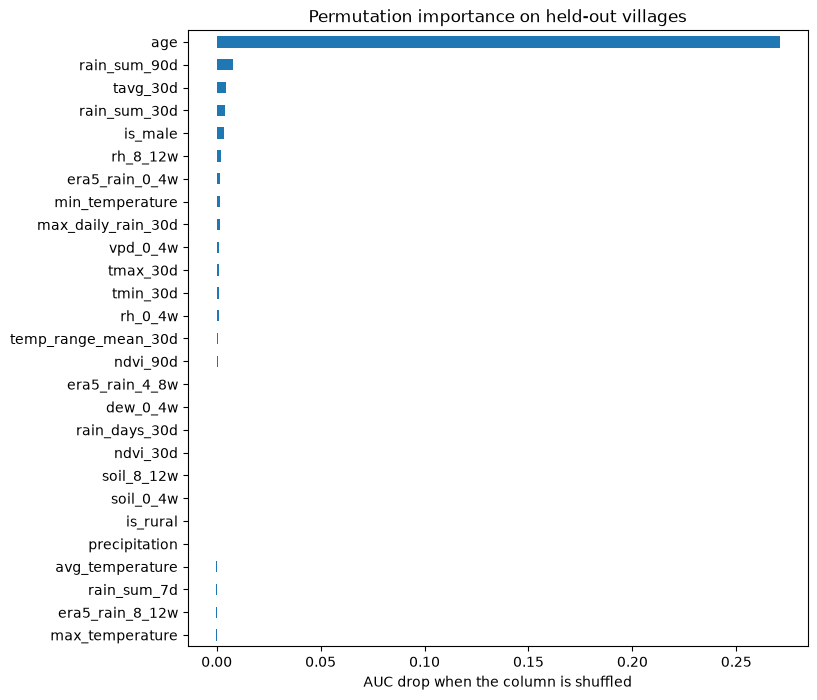

sub3_era5_minus5: 0.8070 (worst split 0.8045)


In [23]:
FEATURES_WITH_ERA5 = FEATURES_ZONE_GENDER + ERA5_FEATURES
cv5.run("sub3_plus_era5", make_model("histgb", HISTGB_SUB2), FEATURES_WITH_ERA5)

# Permutation importance: how much AUC drops when each column is shuffled in held-out villages (~1 minute)
importance = cv5.feature_importance(make_model("histgb", HISTGB_SUB2), FEATURES_WITH_ERA5)
importance_low_to_high = importance.sort_values()
importance_low_to_high.plot(kind="barh", figsize=(8, 8), title="Permutation importance on held-out villages")
plt.xlabel("AUC drop when the column is shuffled")
plt.show()

# The 5 provided climate columns with the lowest importance (all near zero or negative)
DROPPED_CLIMATE = ["max_temperature", "rain_sum_7d", "avg_temperature", "precipitation", "ndvi_30d"]
FEATURES_SUB3 = without(FEATURES_WITH_ERA5, DROPPED_CLIMATE)
cv5.run("sub3_era5_minus5", make_model("histgb", HISTGB_SUB2), FEATURES_SUB3)

sub3: 0.8071 (worst split 0.8054)


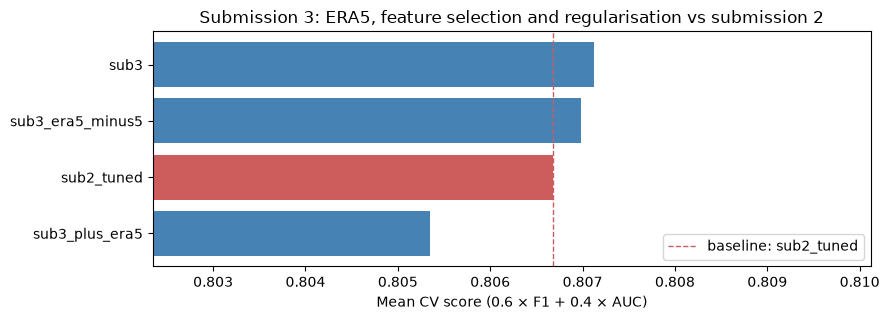

In [24]:
# Stronger-regularisation grid (96 combinations, about 12 minutes). Off by default.
if RUN_SLOW_SEARCHES:
    grid_sub3 = cv5.grid_search("histgb", {
        "max_depth": [2, 3], "learning_rate": [0.02, 0.03], "max_iter": [200, 300],
        "min_samples_leaf": [80, 120, 160, 200], "l2_regularization": [1, 3, 5],
    }, FEATURES_SUB3)
    display(grid_sub3.head(12))

HISTGB_SUB3 = {"max_depth": 3, "learning_rate": 0.02, "max_iter": 300, "min_samples_leaf": 80, "l2_regularization": 3}

cv5.run("sub3", make_model("histgb", HISTGB_SUB3), FEATURES_SUB3)
cv5.compare(["sub3_plus_era5", "sub3_era5_minus5", "sub3"], baseline="sub2_tuned",
            title="Submission 3: ERA5, feature selection and regularisation vs submission 2")

final_model_sub3 = make_model("histgb", HISTGB_SUB3)
# make_submission(final_model_sub3, train, test, FEATURES_SUB3, sample_submission, path=f"{SUBMISSIONS_DIR}/submission3.csv")

**Result:** a tie with submission 2 (0.8071 vs 0.8067). ERA5 alone made things slightly worse (−0.0013); dropping weak columns only undid that, and leaves bigger than 80 didn't help. External weather adds almost nothing here.

### Submission 4: adding `year`

Testing: `year`, because the under-5 rate changes sharply in 2018, plus column subsampling, a HistGB + CatBoost seed ensemble, LightGBM and class weighting.

In [25]:
FEATURES_BASE4 = ["age", "year", "is_rural", "is_male"]
FEATURES_BASE4_CLIMATE = FEATURES_BASE4 + ["rain_sum_30d", "rain_sum_90d", "max_daily_rain_30d", "ndvi_90d",
                                           "tavg_30d", "tmax_30d", "tmin_30d", "temp_range_mean_30d", "min_temperature"]
HISTGB_SUB4 = with_setting(HISTGB_SUB2, "max_features", 0.5)  # column subsampling: each split sees half the columns
CATBOOST_SUB4 = {"depth": 3, "learning_rate": 0.03, "iterations": 400, "l2_leaf_reg": 5, "rsm": 0.5}
SEEDS = [42, 43, 44]

cv5.run("sub4_year", make_model("histgb", HISTGB_SUB2), FEATURES_BASE4)
cv5.run("sub4_year_climate", make_model("histgb", HISTGB_SUB2), FEATURES_BASE4_CLIMATE)
cv5.run("sub4_histgb_subsample", make_model("histgb", HISTGB_SUB4), FEATURES_BASE4)

# Seed ensemble (about 3-4 minutes)
cv5.run("sub4_histgb_3seeds", seed_average("histgb", HISTGB_SUB4, SEEDS), FEATURES_BASE4)
cv5.run("sub4_catboost_3seeds", seed_average("catboost", CATBOOST_SUB4, SEEDS), FEATURES_BASE4)
cv5.blend("sub4_ensemble", ["sub4_histgb_3seeds", "sub4_catboost_3seeds"])

sub4_year: 0.8202 (worst split 0.8183)
sub4_year_climate: 0.8154 (worst split 0.8147)
sub4_histgb_subsample: 0.8202 (worst split 0.8185)
sub4_histgb_3seeds: 0.8206 (worst split 0.8197)
sub4_catboost_3seeds: 0.8201 (worst split 0.8192)
sub4_ensemble: 0.8208 (worst split 0.8199)


In [26]:
# LightGBM (needs `brew install libomp` on macOS; skipped if it can't load)
LIGHTGBM_SUB4 = {"n_estimators": 300, "learning_rate": 0.03, "num_leaves": 8, "max_depth": 3, "min_child_samples": 80,
                 "feature_fraction": 0.5, "bagging_fraction": 0.8, "bagging_freq": 1, "reg_lambda": 1}
try:
    cv5.run("sub4_lightgbm_3seeds", seed_average("lightgbm", LIGHTGBM_SUB4, SEEDS), FEATURES_BASE4)
except (ImportError, OSError) as error:
    print("LightGBM skipped:", error)

# Class weighting (positive x 2), kept as a negative result: it acts like lowering the 0.5 threshold,
# which the rules forbid
HISTGB_SUB4_CLASSWEIGHT = with_setting(HISTGB_SUB4, "class_weight", {0: 1, 1: 2.0})
cv5.run("sub4_histgb_3seeds_classweight", seed_average("histgb", HISTGB_SUB4_CLASSWEIGHT, SEEDS), FEATURES_BASE4)

sub4_lightgbm_3seeds: 0.8174 (worst split 0.8153)
sub4_histgb_3seeds_classweight: 0.8216 (worst split 0.8210)


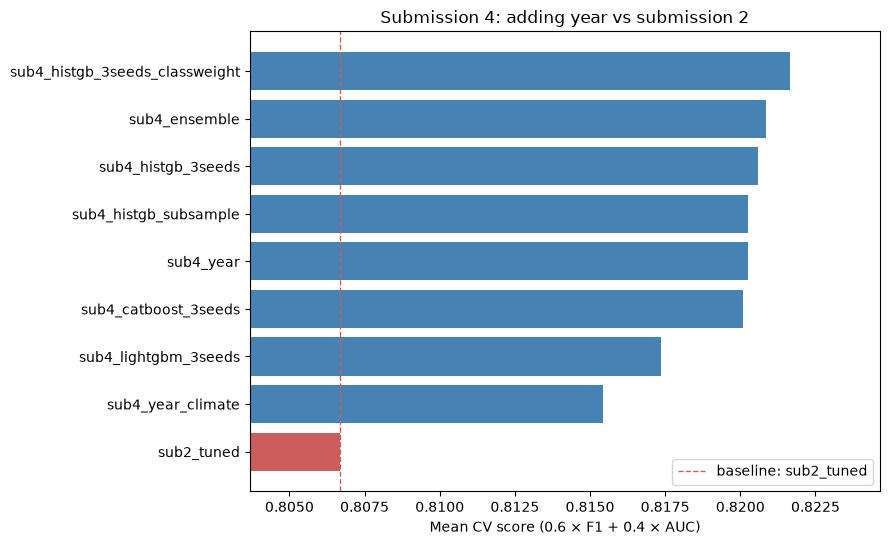

In [27]:
sub4_names = ["sub4_year", "sub4_year_climate", "sub4_histgb_subsample", "sub4_histgb_3seeds",
              "sub4_catboost_3seeds", "sub4_ensemble", "sub4_histgb_3seeds_classweight"]
if "sub4_lightgbm_3seeds" in cv5.results:
    sub4_names.append("sub4_lightgbm_3seeds")
cv5.compare(sub4_names, baseline="sub2_tuned", title="Submission 4: adding year vs submission 2")

final_model_sub4 = AveragedModel([seed_average("histgb", HISTGB_SUB4, SEEDS),
                                  seed_average("catboost", CATBOOST_SUB4, SEEDS)])
# make_submission(final_model_sub4, train, test, FEATURES_BASE4, sample_submission, path=f"{SUBMISSIONS_DIR}/submission4.csv")

**Result:** `year` was the biggest gain of the project: age + year + zone + gender scored **0.8202** (+0.0135, 5/5 splits), and **public jumped to 0.8372**. With `year` in, the climate columns made things *worse*: they had been standing in for time. Subsampling, seeds and the ensemble only added noise-level gains (kept for stability); LightGBM was slightly worse, and class weighting didn't help the ensemble.

### Submission 5: modelling the 2018 step explicitly, and TabPFN

Testing: `post2017` / `under5_post` flags so shallow trees can use the 2018 step directly, a re-tuning grid, and TabPFN v2 (a pretrained model for small tables) in the ensemble.

In [28]:
feature_sets_sub5 = {
    "sub5_+post2017": ["age", "year", "post2017", "is_rural", "is_male"],
    "sub5_+post2017+u5_post": ["age", "year", "post2017", "under5_post", "is_rural", "is_male"],
    "sub5_+post2017+u5_post+adult_post": ["age", "year", "post2017", "under5_post", "adult_post", "is_rural", "is_male"],
    "sub5_post2017_instead_of_year": ["age", "post2017", "is_rural", "is_male"],
}
for name, features in feature_sets_sub5.items():
    cv5.run(name, make_model("histgb", HISTGB_SUB4), features)

FEATURES_SUB5 = feature_sets_sub5["sub5_+post2017+u5_post"]

# Re-tuning grid on these features (30 combinations, about 3 minutes). Off by default; it didn't beat HISTGB_SUB4.
if RUN_SLOW_SEARCHES:
    grid_sub5 = cv5.grid_search("histgb", {
        "min_samples_leaf": [20, 30, 40, 60, 80], "max_depth": [2, 3, 4], "learning_rate": [0.03, 0.05],
        "max_iter": [200], "l2_regularization": [1], "max_features": [0.5],
    }, FEATURES_SUB5)
    display(grid_sub5.head(15))

# Tree ensemble on the new features (about 3-4 minutes)
cv5.run("sub5_histgb_3seeds", seed_average("histgb", HISTGB_SUB4, SEEDS), FEATURES_SUB5)
cv5.run("sub5_catboost_3seeds", seed_average("catboost", CATBOOST_SUB4, SEEDS), FEATURES_SUB5)
cv5.blend("sub5_trees", ["sub5_histgb_3seeds", "sub5_catboost_3seeds"])

sub5_+post2017: 0.8196 (worst split 0.8182)
sub5_+post2017+u5_post: 0.8193 (worst split 0.8182)
sub5_+post2017+u5_post+adult_post: 0.8194 (worst split 0.8182)
sub5_post2017_instead_of_year: 0.8161 (worst split 0.8144)
sub5_histgb_3seeds: 0.8198 (worst split 0.8185)
sub5_catboost_3seeds: 0.8182 (worst split 0.8160)
sub5_trees: 0.8198 (worst split 0.8173)


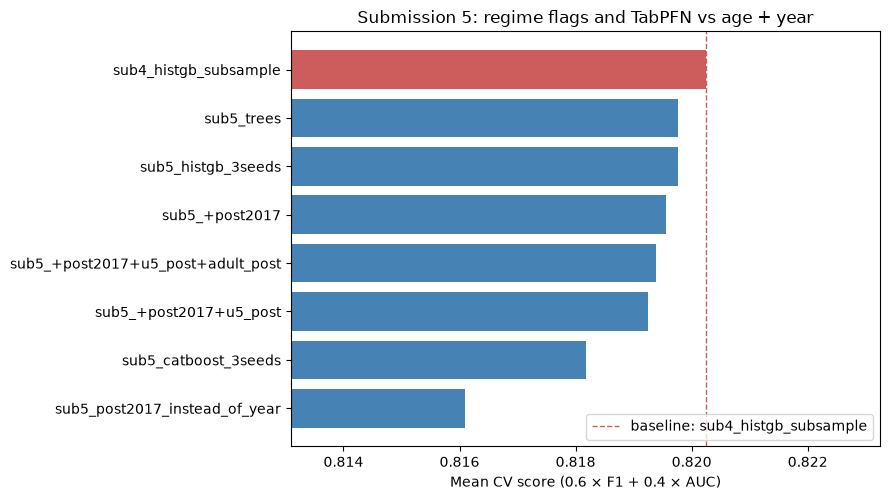

In [29]:
# TabPFN v2 (optional; loads the openly licensed v2 weights explicitly)
TABPFN_PARAMS = {"device": "cpu"}
sub5_names = list(feature_sets_sub5.keys())
sub5_names = sub5_names + ["sub5_histgb_3seeds", "sub5_catboost_3seeds", "sub5_trees"]
if RUN_TABPFN:
    cv5.run("sub5_tabpfn", make_model("tabpfn", TABPFN_PARAMS), FEATURES_SUB5)
    for weight in [0.3, 0.5, 0.7]:
        cv5.blend(f"sub5_trees_tabpfn_{weight}", ["sub5_trees", "sub5_tabpfn"], weights=[1 - weight, weight])
    sub5_names += ["sub5_tabpfn", "sub5_trees_tabpfn_0.3", "sub5_trees_tabpfn_0.5", "sub5_trees_tabpfn_0.7"]

cv5.compare(sub5_names, baseline="sub4_histgb_subsample", title="Submission 5: regime flags and TabPFN vs age + year")

# Submission 5 = trees 0.7 + TabPFN 0.3 (building the TabPFN model needs the `tabpfn` package)
trees_sub5 = AveragedModel([seed_average("histgb", HISTGB_SUB4, SEEDS),
                            seed_average("catboost", CATBOOST_SUB4, SEEDS)])
if RUN_TABPFN:
    final_model_sub5 = AveragedModel([trees_sub5, make_model("tabpfn", TABPFN_PARAMS)], weights=[0.7, 0.3])
    # make_submission(final_model_sub5, train, test, FEATURES_SUB5, sample_submission, path=f"{SUBMISSIONS_DIR}/submission5.csv")

**Result:** in CV nothing beat plain age + year + zone + gender: every variant landed within ±0.002 of 0.820, TabPFN alone was weaker (0.818), and `post2017` instead of `year` lost (−0.004). The drop starts exactly in 2018 for under-5s; adults show no shift. Even so, **public was 0.8414**, my best public score. That's within public-board noise (about 250 rows), so CV and public disagree here.

### Submission 6: diagnostics, and features for pre-2018 infants

Testing: where the remaining errors are, then whether the one group with real signal (pre-2018 infants) can be improved.

In [30]:
# Out-of-fold predictions of the age + year model, averaged over the 5 splits
oof = np.mean(list(cv5.oofs["sub4_histgb_subsample"].values()), axis=0)
labels = train[TARGET]
print(f"Actual positive rate {labels.mean():.3f} | predicted positive {(oof >= 0.5).mean():.3f} | "
      f"mean probability {oof.mean():.3f}")

# Calibration: does the actual rate in each probability bin match the prediction?
probability_bin = pd.cut(oof, [0, 0.3, 0.4, 0.45, 0.5, 0.55, 0.6, 0.7, 0.8, 0.9, 1])
calibration = pd.DataFrame({
    "rows": labels.groupby(probability_bin, observed=True).size(),
    "mean_prediction": pd.Series(oof).groupby(probability_bin, observed=True).mean(),
    "actual_rate": labels.groupby(probability_bin, observed=True).mean(),
})
calibration.round(3)

Actual positive rate 0.651 | predicted positive 0.696 | mean probability 0.651


,rows,mean_prediction,actual_rate
"(0.0, 0.3]",419,0.241,0.239
"(0.3, 0.4]",206,0.348,0.383
"(0.4, 0.45]",211,0.425,0.365
"(0.45, 0.5]",121,0.471,0.496
"(0.5, 0.55]",195,0.526,0.497
"(0.55, 0.6]",318,0.578,0.560
"(0.6, 0.7]",353,0.641,0.666
"(0.7, 0.8]",114,0.739,0.684
"(0.8, 0.9]",100,0.854,0.850
"(0.9, 1.0]",1109,0.945,0.954


In [31]:
def error_summary(group_labels):
    """Errors at the 0.5 threshold, and how well the model ranks deaths, within each group."""
    rows = []
    for name, idx in pd.Series(range(len(train))).groupby(group_labels):
        y_group, p_group = labels.iloc[idx.values], oof[idx.values]
        predicted_positive = p_group >= 0.5
        if y_group.nunique() > 1:
            auc_within = roc_auc_score(y_group, p_group)
        else:
            auc_within = np.nan  # AUC is undefined when a group has only one class
        rows.append({"group": name, "rows": len(y_group), "actual_rate": y_group.mean(),
                     "predicted_positive": predicted_positive.mean(), "auc_within": auc_within,
                     "errors": (predicted_positive != y_group).sum()})
    return pd.DataFrame(rows).round(3)


regime_by_age = np.where(train["year"] >= 2018, "2018+", "before 2018") + " / " + np.where(train["age"] < 5, "under 5", "5+")
error_summary(regime_by_age)

,group,rows,actual_rate,predicted_positive,auc_within,errors
0,2018+ / 5+,208,0.361,0.188,0.668,68
1,2018+ / under 5,548,0.595,0.978,0.587,228
2,before 2018 / 5+,1205,0.434,0.356,0.680,416
3,before 2018 / under 5,1185,0.948,1.000,0.561,62


In [32]:
# Is there any signal left inside each group? |AUC - 0.5| of one column on its own
subgroups = {
    "infants 2018+": (train["age"] == 0) & (train["year"] >= 2018),
    "infants before 2018": (train["age"] == 0) & (train["year"] < 2018),
    "adults 15+ before 2018": (train["age"] >= 15) & (train["year"] < 2018),
}
signal_columns = CLIMATE_COLUMNS + ["elevation", "month"] + ERA5_FEATURES
signal = pd.DataFrame(index=signal_columns)
for group_name, mask in subgroups.items():
    group_rows = train[mask]
    strengths = []
    for column in signal_columns:
        strengths.append(signal_strength(group_rows, column))
    signal[group_name] = strengths
signal["best"] = signal.max(axis=1)
signal = signal.sort_values("best", ascending=False)
signal.head(8).round(3)

,infants 2018+,infants before 2018,adults 15+ before 2018,best
elevation,0.018,0.145,0.003,0.145
tmin_30d,0.005,0.135,0.003,0.135
dew_0_4w,0.011,0.108,0.023,0.108
month,0.044,0.106,0.003,0.106
tavg_30d,0.057,0.097,0.020,0.097
tmax_30d,0.025,0.083,0.015,0.083
rh_0_4w,0.050,0.081,0.004,0.081
rh_8_12w,0.033,0.061,0.048,0.061


**Diagnostics:** the model isn't under-calling positives (69.6% predicted vs 65.1% actual, well calibrated). Most errors sit in **post-2018 infants** (56% rate, nothing separates them) and **adults before 2018** (only age and year carry signal). The one pocket with signal is **pre-2018 infants** (elevation, `tmin_30d`, month), so I add those columns *only* for that group.

sub6_infant_features_leaf80: 0.8206 (worst split 0.8188)
sub6_infant_features_leaf60: 0.8214 (worst split 0.8203)
sub6_infant_features_leaf40: 0.8205 (worst split 0.8182)


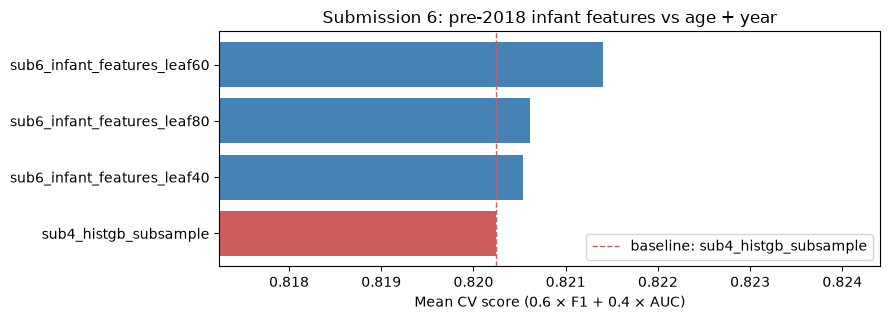

In [33]:
FEATURES_SUB6 = FEATURES_BASE4 + ["elevation_infant_pre", "tmin_30d_infant_pre", "month_infant_pre"]

for leaf in [80, 60, 40]:
    histgb_leaf = with_setting(HISTGB_SUB4, "min_samples_leaf", leaf)
    cv5.run(f"sub6_infant_features_leaf{leaf}", make_model("histgb", histgb_leaf), FEATURES_SUB6)

cv5.compare(["sub6_infant_features_leaf80", "sub6_infant_features_leaf60", "sub6_infant_features_leaf40"],
            baseline="sub4_histgb_subsample", title="Submission 6: pre-2018 infant features vs age + year")

HISTGB_SUB6 = with_setting(HISTGB_SUB4, "min_samples_leaf", 60)
final_model_sub6 = seed_average("histgb", HISTGB_SUB6, SEEDS)
# make_submission(final_model_sub6, train, test, FEATURES_SUB6, sample_submission, path=f"{SUBMISSIONS_DIR}/submission6.csv")

**Result:** with leaf 60, **+0.0012 on all 5 splits** (0.8214), a small but consistent gain; CatBoost was dropped because it lowered the score. Public 0.8366.

### Submission 7: wider tuning on 10 splits, adult features, spline logistic regression

Testing: a random search over HistGB settings (confirmed on 10 splits to avoid lucky picks), climate features for adults only, and a smooth, different model to blend with.

In [34]:
if RUN_SLOW_SEARCHES:  # 80 random settings on 5 splits (~8 minutes), then the top 8 re-scored on 10 splits
    search_sub7 = cv5.random_search("histgb", {
        "min_samples_leaf": [30, 40, 50, 60, 70, 80, 100], "max_depth": [2, 3, 4, 5],
        "learning_rate": [0.01, 0.02, 0.03, 0.05], "max_iter": [100, 200, 300, 400, 600],
        "l2_regularization": [0, 0.5, 1, 3, 5], "max_features": [0.3, 0.5, 0.7, 1.0], "max_leaf_nodes": [4, 8, 15, 31],
    }, FEATURES_SUB6, n_iter=80)
    search_sub7_table = search_sub7.drop(columns="params")
    display(search_sub7_table.head(15))

cv10.run("sub7_sub6_settings", make_model("histgb", HISTGB_SUB6), FEATURES_SUB6)

# The search's top setting (lr 0.01 x 100 trees) was rejected: it predicted ~80% positive by barely training.
# This one, from the same cluster with lr 0.02, ranks deaths better:
HISTGB_SUB7 = {"max_depth": 4, "learning_rate": 0.02, "max_iter": 100, "min_samples_leaf": 80,
               "l2_regularization": 1, "max_features": 0.5, "max_leaf_nodes": 31}
cv10.run("sub7_tuned", make_model("histgb", HISTGB_SUB7), FEATURES_SUB6)
HISTGB_SUB7_SLOW = with_setting(HISTGB_SUB7, "learning_rate", 0.01)
cv10.run("sub7_too_little_training", make_model("histgb", HISTGB_SUB7_SLOW), FEATURES_SUB6)

sub7_sub6_settings: 0.8214 (worst split 0.8199)
sub7_tuned: 0.8234 (worst split 0.8228)
sub7_too_little_training: 0.8239 (worst split 0.8225)


sub7_adult_small: 0.8210 (worst split 0.8189)
sub7_adult_all: 0.8200 (worst split 0.8181)
sub7_spline_logistic: 0.8148 (worst split 0.8131)
sub7_trees_logistic_0.2: 0.8233 (worst split 0.8218)
sub7_trees_logistic_0.3: 0.8228 (worst split 0.8220)


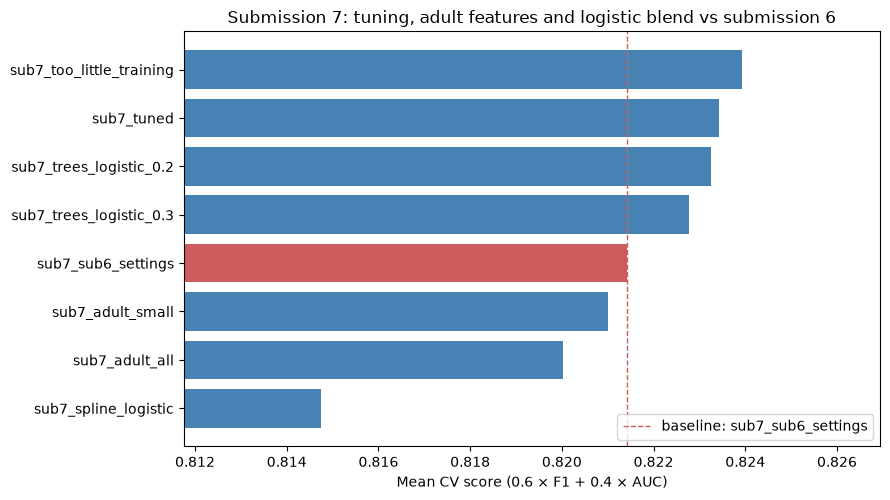

In [35]:
# Climate features for ages 5+ only (blank for children)
adult_small = ["month_adult", "ndvi_90d_adult", "elevation_adult", "rh_8_12w_adult"]
adult_all = adult_small + ["rain_sum_30d_adult", "rain_sum_90d_adult", "max_daily_rain_30d_adult",
                           "tavg_30d_adult", "tmin_30d_adult", "temp_range_mean_30d_adult"]
cv10.run("sub7_adult_small", make_model("histgb", HISTGB_SUB7), FEATURES_SUB6 + adult_small)
cv10.run("sub7_adult_all", make_model("histgb", HISTGB_SUB7), FEATURES_SUB6 + adult_all)

# Spline logistic regression: smooth curves for age and year, plus zone/gender flags
SPLINE_FEATURES = ["age", "year", "post2017", "is_rural", "is_male"]
spline_logistic = make_pipeline(
    ColumnTransformer([
        ("age", SplineTransformer(n_knots=8, degree=3), ["age"]),
        ("year", SplineTransformer(n_knots=5, degree=3), ["year"]),
        ("flags", "passthrough", ["post2017", "is_rural", "is_male"]),
    ]),
    LogisticRegression(C=1.0, max_iter=5000),
)
cv10.run("sub7_spline_logistic", spline_logistic, SPLINE_FEATURES)
for weight in [0.2, 0.3]:
    cv10.blend(f"sub7_trees_logistic_{weight}", ["sub7_tuned", "sub7_spline_logistic"], weights=[1 - weight, weight])

cv10.compare(["sub7_tuned", "sub7_too_little_training", "sub7_adult_small", "sub7_adult_all", "sub7_spline_logistic",
              "sub7_trees_logistic_0.2", "sub7_trees_logistic_0.3"],
             baseline="sub7_sub6_settings", title="Submission 7: tuning, adult features and logistic blend vs submission 6")

SEEDS_SUB7 = [42, 43, 44, 45, 46, 47, 48, 49, 50, 51]  # 10 seeds for the submitted model
final_model_sub7 = seed_average("histgb", HISTGB_SUB7, SEEDS_SUB7)
# make_submission(final_model_sub7, train, test, FEATURES_SUB6, sample_submission, path=f"{SUBMISSIONS_DIR}/submission7.csv")

**Result:** tuning gave **+0.0020 on 10/10 splits** (0.8234). The lr-0.01 version scores about the same, but only by squashing probabilities so ~80% of rows cross 0.5 (it calls 52% of adults positive vs 40% actual), so I rejected it. Adult features and the logistic blend lost. Public 0.8279, lower than CV suggested: more public-board noise.

### Submission 8: averaging, lagged temperature, a separate adult model

Testing: an average of models I'd already validated, temperature 5–11 weeks before death (linked to child malaria deaths at this site), and a model trained on adults only.

sub8_sub5_histgb: 0.8201 (worst split 0.8185)
sub8_sub5_catboost: 0.8183 (worst split 0.8160)
sub8_sub5_trees: 0.8203 (worst split 0.8173)
sub8_sub6: 0.8213 (worst split 0.8200)
sub8_sub7: 0.8230 (worst split 0.8223)
sub8_average_5_6_7: 0.8219 (worst split 0.8204)
sub8_average_6_7: 0.8226 (worst split 0.8211)
sub8_temperature_lags: 0.8207 (worst split 0.8195)
sub8_tmax_lag_only: 0.8224 (worst split 0.8205)
sub8_adult_model: 0.8211 (worst split 0.8198)


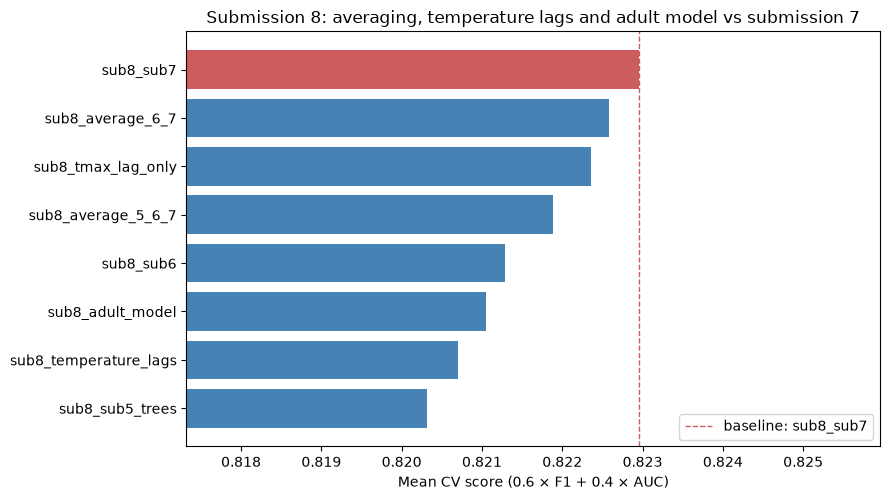

In [36]:
# Average of submissions 5, 6 and 7's models (3 seeds each, about 4 minutes)
cv10.run("sub8_sub5_histgb", seed_average("histgb", HISTGB_SUB4, SEEDS), FEATURES_SUB5)
cv10.run("sub8_sub5_catboost", seed_average("catboost", CATBOOST_SUB4, SEEDS), FEATURES_SUB5)
cv10.blend("sub8_sub5_trees", ["sub8_sub5_histgb", "sub8_sub5_catboost"])
cv10.run("sub8_sub6", seed_average("histgb", HISTGB_SUB6, SEEDS), FEATURES_SUB6)
cv10.run("sub8_sub7", seed_average("histgb", HISTGB_SUB7, SEEDS), FEATURES_SUB6)
cv10.blend("sub8_average_5_6_7", ["sub8_sub5_trees", "sub8_sub6", "sub8_sub7"])
cv10.blend("sub8_average_6_7", ["sub8_sub6", "sub8_sub7"])

# Temperature 5-11 weeks before death
cv10.run("sub8_temperature_lags", make_model("histgb", HISTGB_SUB7), FEATURES_SUB6 + TEMPERATURE_LAG_FEATURES)
cv10.run("sub8_tmax_lag_only", make_model("histgb", HISTGB_SUB7), FEATURES_SUB6 + ["tmax_lag_5_11w"])

# Separate adult model: trained on ages 5+ only; under-5s keep the main model
HISTGB_ADULT = {"max_depth": 3, "learning_rate": 0.03, "max_iter": 200, "min_samples_leaf": 40,
                "l2_regularization": 1, "max_features": 0.5}
adult_features = ["age", "year", "is_rural", "is_male", "month"]
age_split_model = AgeSplitModel(ColumnModel(make_model("histgb", HISTGB_SUB7), FEATURES_SUB6),
                                ColumnModel(make_model("histgb", HISTGB_ADULT), adult_features))
columns_for_split_model = FEATURES_SUB6 + without(adult_features, FEATURES_SUB6)  # each column once
cv10.run("sub8_adult_model", age_split_model, columns_for_split_model)

cv10.compare(["sub8_sub5_trees", "sub8_sub6", "sub8_average_5_6_7", "sub8_average_6_7", "sub8_temperature_lags",
              "sub8_tmax_lag_only", "sub8_adult_model"],
             baseline="sub8_sub7", title="Submission 8: averaging, temperature lags and adult model vs submission 7")

final_model_sub8 = AveragedModel([seed_average("histgb", HISTGB_SUB6, SEEDS),
                                  seed_average("histgb", HISTGB_SUB7, SEEDS_SUB7)])
# make_submission(final_model_sub8, train, test, FEATURES_SUB6, sample_submission, path=f"{SUBMISSIONS_DIR}/submission8.csv")

**Result:** none of it helped. Averaging tied submission 7, lagged temperature lost (−0.001 to −0.004; its only signal is in pre-2018 infants, who are already 97% positive), and the adult model lost on every split (−0.002 to −0.005).

### Submission 9: re-tuning submission 5 (final pick)

Testing: submission 5 had the best public score, so I re-tuned its setup: feature selection, a wide HistGB search, and a CatBoost search, then the blend weights.

sub9_sub5_histgb: 0.8196 (worst split 0.8182)
sub9_drop_year: 0.8158 (worst split 0.8146)
sub9_drop_post2017: 0.8199 (worst split 0.8179)
sub9_drop_under5_post: 0.8196 (worst split 0.8182)
sub9_drop_is_rural: 0.8202 (worst split 0.8186)
sub9_drop_is_male: 0.8139 (worst split 0.8123)
sub9_add_month: 0.8188 (worst split 0.8167)
sub9_add_under5: 0.8193 (worst split 0.8174)
sub9_add_is_infant: 0.8201 (worst split 0.8183)
sub9_add_infant_post: 0.8199 (worst split 0.8174)
sub9_add_elevation_infant_pre: 0.8209 (worst split 0.8186)
sub9_add_tmin_30d_infant_pre: 0.8209 (worst split 0.8189)
sub9_add_month_infant_pre: 0.8202 (worst split 0.8181)


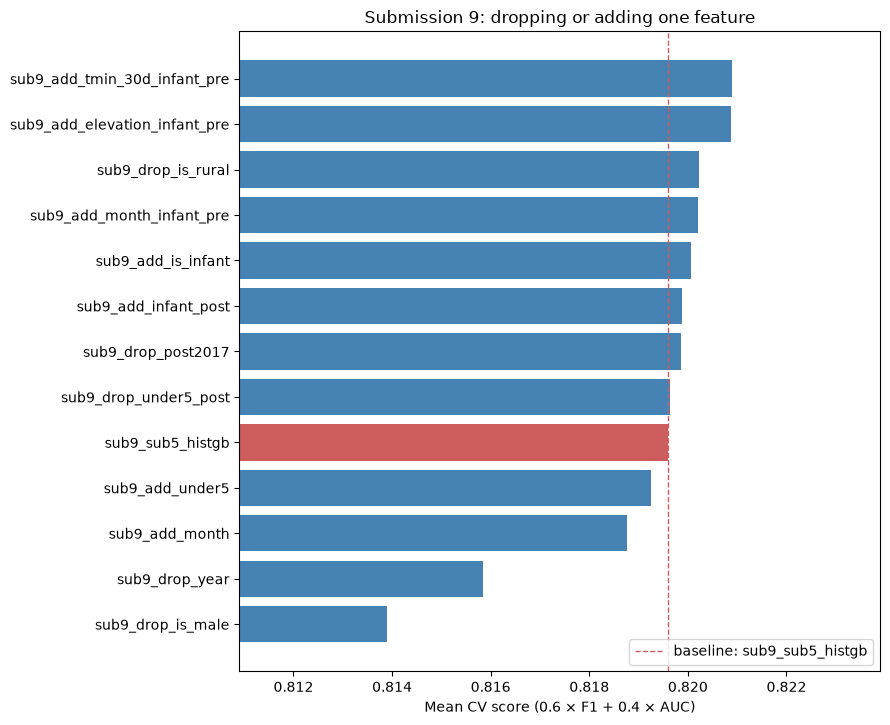

,mean,worst_split,gain_vs_baseline,splits_beating_baseline,pred_pos_rate
sub9_add_tmin_30d_infant_pre,0.8209,0.8189,0.0013,10,0.6919
sub9_add_elevation_infant_pre,0.8209,0.8186,0.0013,8,0.6893
sub9_drop_is_rural,0.8202,0.8186,0.0006,6,0.6896
sub9_add_month_infant_pre,0.8202,0.8181,0.0006,7,0.6909
sub9_add_is_infant,0.8201,0.8183,0.0005,7,0.6864
sub9_add_infant_post,0.8199,0.8174,0.0003,6,0.6737
sub9_drop_post2017,0.8199,0.8179,0.0002,6,0.6919
sub9_drop_under5_post,0.8196,0.8182,0.0000,4,0.6892
sub9_sub5_histgb,0.8196,0.8182,0.0000,0,0.6942
sub9_add_under5,0.8193,0.8174,-0.0003,4,0.6914


In [37]:
cv10.run("sub9_sub5_histgb", make_model("histgb", HISTGB_SUB4), FEATURES_SUB5)

# Feature selection: drop each feature in turn, then try adding candidates (about 2 minutes)
selection_runs = []
for feature in FEATURES_SUB5[1:]:  # age always stays
    name = f"sub9_drop_{feature}"
    cv10.run(name, make_model("histgb", HISTGB_SUB4), without(FEATURES_SUB5, [feature]))
    selection_runs.append(name)

candidates = ["month", "under5", "is_infant", "infant_post", "elevation_infant_pre", "tmin_30d_infant_pre", "month_infant_pre"]
for feature in candidates:
    name = f"sub9_add_{feature}"
    cv10.run(name, make_model("histgb", HISTGB_SUB4), FEATURES_SUB5 + [feature])
    selection_runs.append(name)

cv10.compare(selection_runs, baseline="sub9_sub5_histgb", title="Submission 9: dropping or adding one feature")

**Result:** `year` and `is_male` are essential; `tmin_30d_infant_pre` is the clearest gain (+0.0013, 10/10 splits). I checked a few combinations and kept submission 5's features plus that one.

In [38]:
FEATURES_SUB9 = FEATURES_SUB5 + ["tmin_30d_infant_pre"]

if RUN_SLOW_SEARCHES:  # 100 HistGB settings (~10 min) and 20 CatBoost settings (~10 min)
    search_sub9_histgb = cv5.random_search("histgb", {
        "min_samples_leaf": [20, 30, 40, 60, 80, 100, 150], "max_depth": [2, 3, 4, 5, 6],
        "learning_rate": [0.01, 0.02, 0.03, 0.05, 0.08, 0.1], "max_iter": [50, 100, 200, 300, 500],
        "l2_regularization": [0, 0.5, 1, 3, 5, 10], "max_features": [0.3, 0.5, 0.7, 1.0], "max_leaf_nodes": [4, 8, 15, 31],
    }, FEATURES_SUB9, n_iter=100)
    search_sub9_histgb_table = search_sub9_histgb.drop(columns="params")
    display(search_sub9_histgb_table.head(15))
    cv3 = Experiments(train, n_splits=5, split_seeds=[0, 1, 2])  # 3 splits: CatBoost is slower
    search_sub9_catboost = cv3.random_search("catboost", {
        "depth": [2, 3, 4, 5], "learning_rate": [0.01, 0.02, 0.03, 0.05, 0.1], "iterations": [200, 400, 700],
        "l2_leaf_reg": [1, 3, 5, 10, 20], "rsm": [0.5, 0.75, 1.0], "random_strength": [0.5, 1, 2, 5],
        "bagging_temperature": [0, 0.5, 1],
    }, FEATURES_SUB9, n_iter=20)
    search_sub9_catboost_table = search_sub9_catboost.drop(columns="params")
    display(search_sub9_catboost_table.head(10))

# Winners after confirming the top settings on 10 splits (both beat the old settings on 10/10 splits)
HISTGB_SUB9 = {"min_samples_leaf": 20, "max_depth": 5, "learning_rate": 0.02, "max_iter": 100,
               "l2_regularization": 5.0, "max_features": 0.3, "max_leaf_nodes": 8}
CATBOOST_SUB9 = {"depth": 5, "learning_rate": 0.01, "iterations": 400, "l2_leaf_reg": 3.0,
                 "rsm": 1.0, "random_strength": 1.0, "bagging_temperature": 0.5}

cv10.run("sub9_histgb", seed_average("histgb", HISTGB_SUB9, SEEDS), FEATURES_SUB9)
cv10.run("sub9_catboost", seed_average("catboost", CATBOOST_SUB9, SEEDS), FEATURES_SUB9)
weights_sub9 = cv10.weight_search(["sub9_histgb", "sub9_catboost"], step=0.1)
weights_sub9.round(4)

sub9_histgb: 0.8233 (worst split 0.8224)
sub9_catboost: 0.8217 (worst split 0.8203)


,w_sub9_histgb,w_sub9_catboost,mean,worst_split,pred_pos_rate
0,0.8,0.2,0.8236,0.8226,0.7072
1,0.7,0.3,0.8236,0.8223,0.7047
2,0.6,0.4,0.8236,0.8223,0.7024
3,0.9,0.1,0.8235,0.8223,0.7108
4,0.5,0.5,0.8234,0.8222,0.6999
5,1.0,0.0,0.8233,0.8224,0.7135
6,0.4,0.6,0.8231,0.8217,0.6974
7,0.3,0.7,0.8227,0.8210,0.6956
8,0.2,0.8,0.8222,0.8205,0.6937
9,0.1,0.9,0.8220,0.8206,0.6921


sub9: 0.8236 (worst split 0.8223)


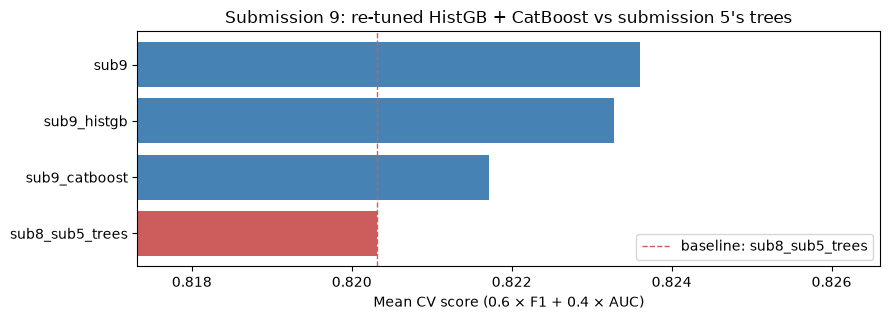

In [39]:
cv10.blend("sub9", ["sub9_histgb", "sub9_catboost"], weights=[0.7, 0.3])
cv10.compare(["sub9_histgb", "sub9_catboost", "sub9"], baseline="sub8_sub5_trees",
             title="Submission 9: re-tuned HistGB + CatBoost vs submission 5's trees")

# Submission 9 = HistGB 0.7 + CatBoost 0.3 (no TabPFN: it added nothing in CV)
final_model_sub9 = AveragedModel([seed_average("histgb", HISTGB_SUB9, SEEDS),
                                  seed_average("catboost", CATBOOST_SUB9, SEEDS)], weights=[0.7, 0.3])
# make_submission(final_model_sub9, train, test, FEATURES_SUB9, sample_submission, path=f"{SUBMISSIONS_DIR}/submission9.csv")

**Result:** **CV 0.8236**, +0.0038 over submission 5's blend on the same splits, with a much better worst split. All blend weights from 0.5 to 0.8 HistGB scored the same, so I used 0.7 / 0.3. **Public 0.8354** (HistGB alone, 9b: 0.8332).

### Submission 10: finer search and new hyperparameters

Testing: a finer search around submission 9's settings, plus hyperparameters I hadn't tried (HistGB: `max_bins`, `interaction_cst`, `monotonic_cst`; CatBoost: `border_count`, `leaf_estimation_iterations`, `Lossguide` / `Depthwise` trees, row subsampling).

sub10_catboost_symmetric: 0.8227 (worst split 0.8209)
sub10_catboost_lossguide: 0.8222 (worst split 0.8205)
sub10: 0.8237 (worst split 0.8225)


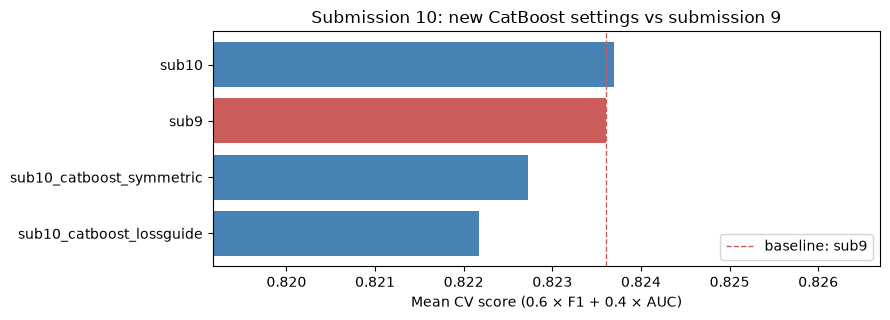

In [40]:
if RUN_SLOW_SEARCHES:  # about 20 minutes: 100 HistGB settings, then 2 x 12 CatBoost settings
    def column_positions(names):
        """interaction_cst needs column positions in FEATURES_SUB9, not names."""
        positions = []
        for name in names:
            positions.append(FEATURES_SUB9.index(name))
        return positions

    time_age_groups = [column_positions(["age", "year", "post2017", "under5_post"]),
                       column_positions(["age", "is_rural", "is_male"]),
                       column_positions(["age", "year", "tmin_30d_infant_pre"])]
    search_sub10_histgb = cv5.random_search("histgb", {
        "min_samples_leaf": [10, 15, 20, 30, 40], "max_depth": [4, 5, 6, 8], "learning_rate": [0.015, 0.02, 0.025, 0.03],
        "max_iter": [75, 100, 125, 150], "l2_regularization": [3, 5, 7, 10, 15], "max_features": [0.2, 0.3, 0.4],
        "max_leaf_nodes": [6, 8, 10, 12], "max_bins": [32, 64, 128, 255],
        "interaction_cst": [None, "pairwise", time_age_groups],
        "monotonic_cst": [None, {"year": -1}],
    }, FEATURES_SUB9, n_iter=100)
    search_sub10_histgb_table = search_sub10_histgb.drop(columns="params")
    display(search_sub10_histgb_table.head(15))

# The best new CatBoost settings from each search (HistGB found nothing better than submission 9's)
CATBOOST_SUB10_SYMMETRIC = {"depth": 5, "learning_rate": 0.0075, "iterations": 400, "l2_leaf_reg": 2, "rsm": 1.0,
                            "random_strength": 0.5, "bagging_temperature": 1, "border_count": 128,
                            "leaf_estimation_iterations": 5}
CATBOOST_SUB10_LOSSGUIDE = {"grow_policy": "Lossguide", "depth": 4, "learning_rate": 0.01, "iterations": 300,
                            "l2_leaf_reg": 10, "min_data_in_leaf": 80, "bootstrap_type": "Bernoulli",
                            "subsample": 0.6, "rsm": 1.0}

cv10.run("sub10_catboost_symmetric", seed_average("catboost", CATBOOST_SUB10_SYMMETRIC, SEEDS), FEATURES_SUB9)
cv10.run("sub10_catboost_lossguide", seed_average("catboost", CATBOOST_SUB10_LOSSGUIDE, SEEDS), FEATURES_SUB9)
cv10.blend("sub10", ["sub9_histgb", "sub10_catboost_symmetric", "sub10_catboost_lossguide"], weights=[0.6, 0.2, 0.2])
cv10.compare(["sub10_catboost_symmetric", "sub10_catboost_lossguide", "sub10"], baseline="sub9",
             title="Submission 10: new CatBoost settings vs submission 9")

final_model_sub10 = AveragedModel([seed_average("histgb", HISTGB_SUB9, SEEDS),
                                   seed_average("catboost", CATBOOST_SUB10_SYMMETRIC, SEEDS),
                                   seed_average("catboost", CATBOOST_SUB10_LOSSGUIDE, SEEDS)], weights=[0.6, 0.2, 0.2])
# make_submission(final_model_sub10, train, test, FEATURES_SUB9, sample_submission, path=f"{SUBMISSIONS_DIR}/submission10.csv")

**Result:** a tie with submission 9 (0.8237 vs 0.8236). The new HistGB hyperparameters didn't help (default bins and no constraints were best on average), and the new CatBoost settings were within noise. Submission 9's settings were already at the ceiling.

## 6. Final comparison

The main submissions scored on the same 10 grouped splits.

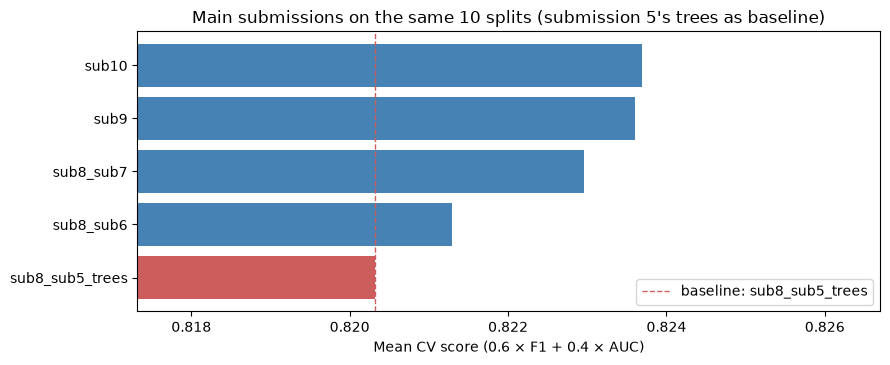

,mean,worst_split,gain_vs_baseline,splits_beating_baseline,pred_pos_rate
sub10,0.8237,0.8225,0.0034,10,0.7034
sub9,0.8236,0.8223,0.0033,10,0.7047
sub8_sub7,0.8230,0.8223,0.0026,10,0.7141
sub8_sub6,0.8213,0.8200,0.0010,9,0.6944
sub8_sub5_trees,0.8203,0.8173,0.0000,0,0.6865


In [41]:
cv10.compare(["sub8_sub6", "sub8_sub7", "sub9", "sub10"], baseline="sub8_sub5_trees",
             title="Main submissions on the same 10 splits (submission 5's trees as baseline)")

## 7. Conclusion

| Submission | Key change | CV | Public LB |
|---|---|---|---|
| 1 | age + raw climate | 0.8000 | 0.8055 |
| 4 | **+ year** (biggest gain) | 0.8208 | 0.8372 |
| 5 ⭐ | regime flags, + TabPFN | ~0.820 | **0.8414** |
| 6 | pre-2018 infant features | 0.8214 | 0.8366 |
| 7 | tuned HistGB, 10 seeds | 0.8234 | 0.8279 |
| 9 ⭐ | re-tuned HistGB + CatBoost | **0.8236** | 0.8354 |
| 10 | new CatBoost settings | 0.8237 | not recorded |



- **What mattered:** age, then `year` (the 2018 recording change), then zone and gender. Tuning and the pre-2018 infant features added small, consistent gains.
- **What didn't:** climate features (raw, engineered, ERA5, lagged temperature), adult-specific models, TabPFN, logistic and LightGBM blends. Climate signal in this data is weak once `year` is in.
- **Ceiling:** five different model types all plateau at about 0.820–0.824 grouped CV.